#### Create 2D toy case
* Development of a 2D VSAFT Groundwater Model
* Training dataset generation 

In [2]:
import h5py
import numpy as np
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from gstools.random import MasterRNG
from scipy.spatial.distance import cdist
from sle import *

#### 2D groundwater model with time varied boundary
* Domin                  : 1500 (m) * 1800 (m)
* Element size           : 30   (m)
* K scale for Silty sand : 1.25  (m/day) 
* Ss                     : 0.0005
* Simulation period      : 120  (days) 
* Constant head bc       : right
* River stage bc         : left

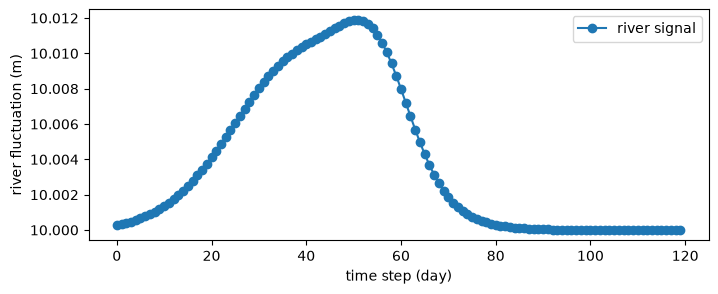

In [3]:
# set river stage signal

period = 120 # day
time_steps = np.linspace(0, period-1, period)

# set time varied signal (Sythetic)
# sigs = np.sin(2*np.pi*(time_steps/period)) + 10
# t = np.linspace(0, 100, 1000)

ampli_1, ampli_2 = 0.01, 0.005
t_1, t_2   = 40, 55
std_1, std_2 = 15, 7 

# sigs =  (  ampli_1 * np.exp(-((time_steps - t_1)**2) / (2 * std_1**2))  )  + 10
sigs =  (  ampli_1 * np.exp(-((time_steps - t_1)**2) / (2 * std_1**2))  + ampli_2 * np.exp(-((time_steps - t_2)**2) / (2 * std_2**2))  ) + 10

# set time varied signal (Real data)
# df_river = pd.read_csv(Path.cwd()/"river_data.dat", sep='\t')
# df_sig = df_river['head'].rolling(window = 20).mean()
# sigs = df_sig.iloc[450 : 450 + period].values
# set initial head
init_h = sigs[0]
df_sig = pd.DataFrame(sigs, columns= ['river'])
df_sig.to_csv('river_sigs.csv', index=False)

fig, ax = plt.subplots(figsize = (8, 3))
plt.plot(time_steps, sigs, '-o', label = "river signal")
plt.xlabel("time step (day)")
plt.legend()
plt.ylabel("river fluctuation (m)")
plt.show()


In [4]:
# Simulation control (unit: meter, day)
project_name = 'toy_case_2D'
forward_dir = os.path.join(os.getcwd(), 'toy_case')
simulation_control = ('2D', 'transient', 'confined')  # dimension, problem, aquifer

# Geometry control
dx = np.array([30] *50)
dy = np.array([30] *60)

start_coord = (0,  0)           # origin coordinate (x0, y0)
element_num = (50, 60)        # element number in each direction (e_x, e_y)
element_spacing = (dx, dy)      # element spacing in each direction (len(dx) = e_x)

# initial condition
init_paras = (init_h, 0, 1.25, 0.0005, 0.4) # init_h, init_flux, init_K, init_Ss, porosity

# boundary condition
# Using time varied head boundary

# injection
const_rate = 0
inj_time = (0, 0)
inj_1 = ((900, 900), 'inj', {'rate':const_rate, 'time': inj_time})


# observation well info
obs_well_num = 24
# obs_cor_list = (
#     (60, 90),   (210, 510),   (480, 300),   (1140, 270),     (1230, 450), 
# )
# obs = [ ((x, y), f'Obs_{i+1}') for i, (x, y) in enumerate(obs_cor_list) ]

# time info for transient
flag = 'each_time_step'
dt, dt_max, dt_mul, t_max, max_red = (1, 1, 1, period, 2)
time = (dt, dt_max, dt_mul, t_max, max_red, flag)                

In [5]:
# sleio
ty_model = sle_io(project_name, forward_dir)

# Geometry 
ty_model.set_parameters(simulation_control)
ty_model.create_geometry(start_coord, element_num, element_spacing)
ty_model.create_initial(init_paras)

# Boundary
df_ele_coor = ty_model.df_coordinate.copy()
df_node_coor = ty_model.df_node_coordinate.copy()


right_cor_list = tuple(
        zip(
                df_node_coor.loc[df_node_coor['x'] == df_node_coor['x'].max()]['x'], 
                df_node_coor.loc[df_node_coor['x'] == df_node_coor['x'].max()]['y'],
        )
    )

river_cor_list = tuple(
        zip(
                df_node_coor.loc[df_node_coor['x'] == df_node_coor['x'].min()]['x'], 
                df_node_coor.loc[df_node_coor['x'] == df_node_coor['x'].min()]['y'],
        )
    )

bc_cor_list = right_cor_list + river_cor_list

boundary = ('coordinate', bc_cor_list, 'head')  # method, value, bc_type
ty_model.create_boundary(boundary)

# Sources
# df_obs_cand = df_node_coor.loc[ ~df_node_coor['y'].isin([df_node_coor['x'].max(), df_node_coor['x'].min()])].copy()
# df_obs_coor = df_obs_cand.sample(n=19, random_state = 121)
# obs_cor_list = tuple(zip(df_obs_coor['x'], df_obs_coor['y']))
# obs = [ ((x, y), f'Obs_{i+1}') for i, (x, y) in enumerate(zip(df_obs_coor['x'], df_obs_coor['y'])) ]

df_obs_cand = df_node_coor.loc[ 
    ~ ( 
       df_node_coor['x'].isin([ df_node_coor['x'].max(), df_node_coor['x'].min()]) 
       | df_node_coor['y'].isin([ df_node_coor['y'].max(), df_node_coor['y'].min()])        
    )
].copy()

coords = df_obs_cand[['x', 'y']].to_numpy()

rng = np.random.default_rng(19991213)
selected_idx = [rng.integers(len(coords))]
min_dist = cdist(coords, coords[selected_idx]).min(axis=1)

for _ in range(obs_well_num - 1):
    next_idx = np.argmax(min_dist)
    selected_idx.append(next_idx)

    dist = cdist(coords, coords[[next_idx]]).ravel()
    min_dist = np.minimum(min_dist, dist)

df_obs_coor = df_obs_cand.iloc[selected_idx].copy()
obs_cor_list = tuple(zip(df_obs_coor['x'], df_obs_coor['y']))
obs = [  ((x, y), f'Obs_{i+1}') for i, (x, y) in enumerate(obs_cor_list)]

ty_model.add_stress(1, time, obs, (inj_1,))
ty_model.create_boundary(boundary)
ty_model.create_source()
ty_model.create_observation()

# simulation 
ty_model.create_times()
ty_model.create_function()
ty_model.create_simulation()
ty_model.create_problem()
ty_model.write_forward_input()


Project: toy_case_2D
Work on folder:C:\Users\Ethan\Desktop\ethan\專案\HTNN-2D\toy_case
Simulation in '2D' case, 'confined' aquifer under 'transient' state
Ready for forward simulation!


In [6]:
# set river boundary
river_node_idx  = df_node_coor[df_node_coor['x'] == df_node_coor['x'].min()]['node_id'].values
node_number = len(river_node_idx)

# Create time_vary_h_bc format
signal =  np.expand_dims(sigs, axis = 0)
signals = np.repeat(np.array(signal), node_number , axis=0) # (node_number, time_step_number)

df_ele_num = pd.DataFrame([node_number])
df_t_length = pd.DataFrame([len(time_steps)])

bc_node_idx = np.expand_dims(river_node_idx, axis = 1)
lower_matrix = np.concat([bc_node_idx, signals], axis = 1) 

df_lower = pd.DataFrame(lower_matrix)
df_time_step = pd.DataFrame([np.append(np.nan, time_steps)])
df = pd.concat([df_ele_num, df_t_length, df_time_step, df_lower], axis = 0)
df.to_csv(ty_model.work_dir/"time_vary_h_bc.dat", sep="\t", header=False, index=False)

In [9]:
# sythetic random field
rf_mean = 1.25
rf_variance = 0.75
seed = np.random.randint(1, 1000, 1) + 2026
ln_var = np.log1p(rf_variance / rf_mean**2)
ln_mean = np.log(rf_mean) - 0.5 * ln_var
correlation_scale = [300,300]  # correlation for X, Y, Z direction      
ty_model.random_gaussian_field(correlation_scale, ln_mean, ln_var, seed)   

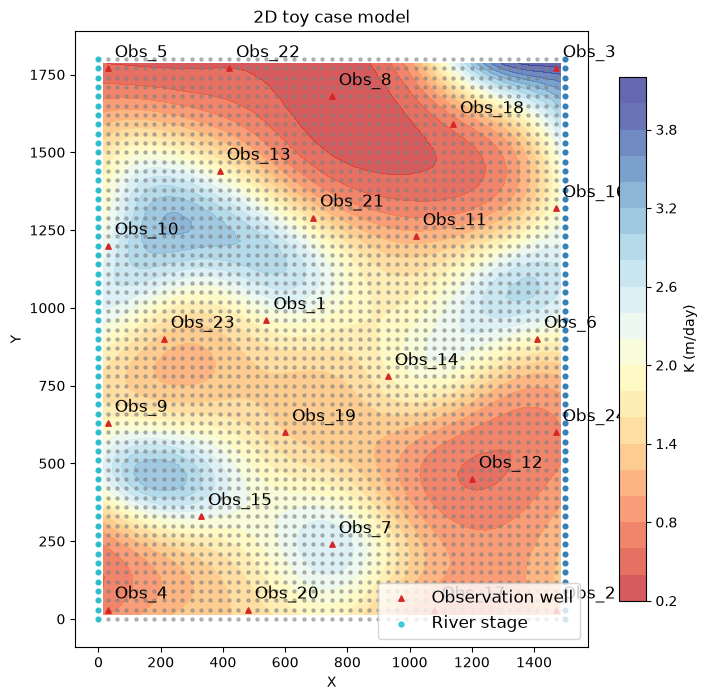

In [10]:
# plot 2D model
fig, ax = plt.subplots(figsize = (8, 8))

# random field
cf = ax.tricontourf( df_ele_coor['x'], df_ele_coor['y'], ty_model.grf, levels=20, cmap='RdYlBu', vmin = 0, vmax = 4, alpha = 0.75)
fig.colorbar(cf, ax=ax, shrink = 0.85, fraction=0.08, label='K (m/day)')

# grid
ax.scatter( df_node_coor['x'], df_node_coor['y'], s=5, color='gray', alpha = 0.5)

# obs well
for i, ((x_w, y_w), name) in enumerate(obs):
    ax.scatter(  x_w, y_w, color='tab:red', marker='^', s=15, zorder=2, label='Observation well' if i == 0 else None)
    ax.annotate( name, (x_w, y_w), xytext=(5, 8), textcoords='offset points', fontsize=12)
    
# boundarys
for i, (x_bc, y_bc) in enumerate(right_cor_list):
    ax.scatter( x_bc, y_bc, s=12, color='tab:blue', alpha = 0.8)

# for i, (x_bc, y_bc) in enumerate(down_cor_list):
#     ax.scatter( x_bc, y_bc, s=12, color='tab:blue', alpha = 0.8, label='Constant head' if i == 0 else None)
    
for i, (x_bc, y_bc) in enumerate(river_cor_list):
    ax.scatter( x_bc, y_bc, s=12, color='tab:cyan', alpha = 0.8, label='River stage' if i == 0 else None)

ax.set_aspect('equal')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('2D toy case model')
ax.legend( loc='lower right', fontsize=12, frameon=True)
plt.show()


In [ ]:
# run forward simulation
ty_model.run_forward(print_output = True)
ty_model.read_stress_FwdObs()

fig, ax = plt.subplots(figsize = (8,3))
for _, name in obs:
    ty_model.stress_result['stress_1'][name].plot(label = name)
    ax.set_xlabel("time step")

### Training Dataset

In [11]:
# random field generation (Y)
ens_num = 5000
rng = MasterRNG(20261114)
rf_fname = "material_test_3"

for i in range(ens_num):
    
    sle = sle_io('random field', forward_dir, verbose=False)
    rf_folder = sle.work_dir / rf_fname
    rf_folder.mkdir(parents = True, exist_ok = True)
    
    rf_mean = 1.25
    rf_variance = 1
    ln_var = np.log1p(rf_variance / rf_mean**2)
    ln_mean = np.log(rf_mean) - 0.5 * ln_var
    
    sle.dimension = 2
    sle.total_element_num  = 50*60
    sle.df_coordinate = df_ele_coor
    sle.random_gaussian_field( [300,300], ln_mean, ln_var, int(rng()))
    
    df_material = pd.DataFrame({'K': sle.grf})
    df_material.to_csv(rf_folder/f'material_{i+1}.dat', header=True, index=  False)

#### Run simulation head

In [ ]:
# forward simulation (X)
h_fname = 'h_test_3'
df_m = ty_model.df_material.copy()

for i in range(ens_num):
    
    sle_sim = sle_io('run simulation', forward_dir, verbose=False)
    
    h_folder = sle_sim.work_dir / rf_fname
    h_folder.mkdir(parents = True, exist_ok = True)
    df_rf = pd.read_csv(h_folder / f'material_{i+1}.dat')
    rf_k = df_rf['K'].values
    
    sle_sim.dimension = 2
    sle_sim.problem_type = 2
    sle_sim.df_material = df_m
    sle_sim.init_paras = init_paras
    sle_sim.total_element_num = 50*60
    
    
    sle_sim.run_forward(rf_k)
    sle_sim.read_stress_FwdObs()
    df_head = sle_sim.stress_result['stress_1']
    
    df_head.to_csv(h_folder/f'head_{i+1}.dat', header = True, index =  False)
    

In [ ]:
# collect training dataset
input_list = []
output_list = []

for i in range(ens_num):
    
    # Input X
    select_time_idx = np.arange(1, 100, 2)
    
    df_h = pd.read_csv(h_folder/f'head_{i+1}.dat')
    
    if df_h.shape != (120, 24):
        print(f'Skip ensemble {i+1}: invalid shape {df_h.shape}')
        continue
        
    df_h['river'] = sigs - sigs[0]
    input_list.append(df_h.iloc[select_time_idx].values)
    
    # Output Y
    df_m = pd.read_csv(rf_folder/f'material_{i+1}.dat')
    rf_k = df_m['K'].values
    output_list.append(rf_k.reshape(element_num[1], element_num[0]))  
    

Skip ensemble 2133: invalid shape (121, 24)
Skip ensemble 2226: invalid shape (661, 24)
Skip ensemble 2948: invalid shape (129, 24)
Skip ensemble 3021: invalid shape (121, 24)
Skip ensemble 3422: invalid shape (485, 24)
Skip ensemble 4584: invalid shape (528, 24)


In [ ]:
# Save as hdf5 file
data_fname = "training_data"

X_data = np.stack( input_list, axis=0 )
Y_data = np.stack( output_list, axis=0 )

X_data = np.expand_dims(X_data, axis=1)
Y_data = np.expand_dims(Y_data, axis=1)

print(f"X shape: {X_data.shape}")
print(f"Y shape: {Y_data.shape}")

if X_data.shape[1:] != (1, 50, 25):
    raise ValueError( f"Invalid X shape: {X_data.shape}")

if Y_data.shape[1:] != (1, 60, 50):
    raise ValueError( f"Invalid Y shape: {Y_data.shape}")

training_dir = os.path.join( forward_dir , data_fname)
os.makedirs( training_dir, exist_ok=True)


# Save to h5df
X_path = os.path.join( training_dir, f"input_X_head_{ty_model.project_name}_2.hdf5" )
Y_path = os.path.join( training_dir, f"output_Y_para_{ty_model.project_name}_2.hdf5")

with h5py.File(X_path, "w") as f_x:
    f_x.create_dataset( "dataset", data = X_data, compression="gzip")
with h5py.File(Y_path, "w") as f_y:
    f_y.create_dataset( "dataset", data = Y_data, compression="gzip" )

print("\n==========================================")
print("HDF5 Saved")
print("==========================================")
print(f"X file: {X_path}")
print(f"Y file: {Y_path}")
print(f"X shape: {X_data.shape}")
print(f"Y shape: {Y_data.shape}")

X shape: (4994, 1, 50, 25)
Y shape: (4994, 1, 60, 50)

HDF5 Saved
X file: c:\Users\Ethan\Desktop\ethan\專案\HTNN-2D\toy_case\training_data\input_X_head_toy_case_2D_2.hdf5
Y file: c:\Users\Ethan\Desktop\ethan\專案\HTNN-2D\toy_case\training_data\output_Y_para_toy_case_2D_2.hdf5
X shape: (4994, 1, 50, 25)
Y shape: (4994, 1, 60, 50)
